# 02 | GPS trajectory EDA

Inspect raw sampling and geographical extent, then demonstrate conservative preprocessing. Partition labels are retained throughout.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/data/dataset_loader.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the PathSnap repository or notebooks folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RAW = Path(os.environ.get("PATHSNAP_RAW_ROOT", str(ROOT / "data/raw")))
EVIDENCE = ROOT / "results/member1"
if not (EVIDENCE / "processing_summary.csv").exists():
    raise RuntimeError("Run python -m src.data.prepare_member1 first")
inventory = pd.read_csv(EVIDENCE / "dataset_inventory.csv", dtype={"trip_id": str})
summary = pd.read_csv(EVIDENCE / "processing_summary.csv", dtype={"trip_id": str})
display(inventory.groupby("partition").agg(trips=("trip_id", "size"), gps=("gps_observations", "sum")))

,trips,gps
partition,,
student_test,10,19160
train,80,208417


,count,mean,std,min,50%,90%,99%,max
partition,,,,,,,,
student_test,19150.0,1.057441,1.663988,1.0,1.0,1.0,2.0,210.0
train,208337.0,2.181237,354.852204,1.0,1.0,1.0,3.0,153064.0


Fraction of steps exactly 1 second: 0.9668200820266653


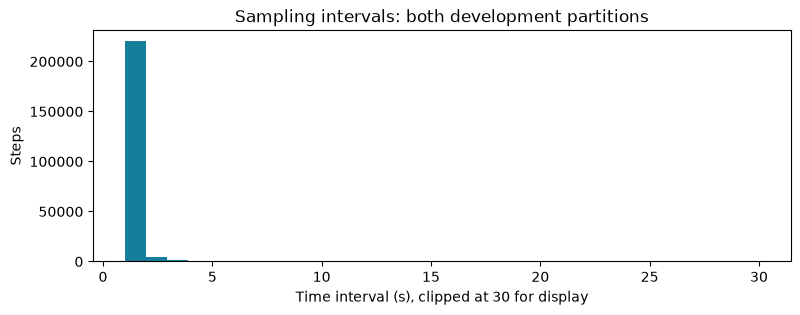

In [2]:
from src.data.dataset_loader import load_trip
from src.preprocessing.gps_cleaning import clean_track
from src.candidates.candidate_utils import RoadNetwork
import matplotlib.pyplot as plt
intervals = []
for row in inventory.itertuples(index=False):
    trip = load_trip(RAW, row.partition, row.trip_id, include_reference=False)
    intervals.append(pd.DataFrame({"partition": row.partition, "dt_s": trip.track.timestamp_s.diff().dropna()}))
intervals = pd.concat(intervals, ignore_index=True)
display(intervals.groupby("partition").dt_s.describe(percentiles=[.5, .9, .99]))
print("Fraction of steps exactly 1 second:", float(np.isclose(intervals.dt_s, 1).mean()))
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(intervals.dt_s.clip(upper=30), bins=30, color="#167d9a")
ax.set(xlabel="Time interval (s), clipped at 30 for display", ylabel="Steps", title="Sampling intervals: both development partitions")
plt.show()

,observation_id,timestamp_s,dt_s,speed_mps,heading_valid,gap_before
0,0,1.0,0.0,0.000000,False,True
1,1,2.0,1.0,43.632247,True,False
2,2,3.0,1.0,49.319383,True,False
3,3,4.0,1.0,55.214278,True,False
4,4,5.0,1.0,43.612784,True,False
5,5,6.0,1.0,46.420259,True,False
6,6,7.0,1.0,46.290073,True,False
7,7,8.0,1.0,40.700579,True,False
8,8,9.0,1.0,50.345099,True,False
9,9,10.0,1.0,34.529666,True,False


Rejected: 0 Metric CRS: 32632


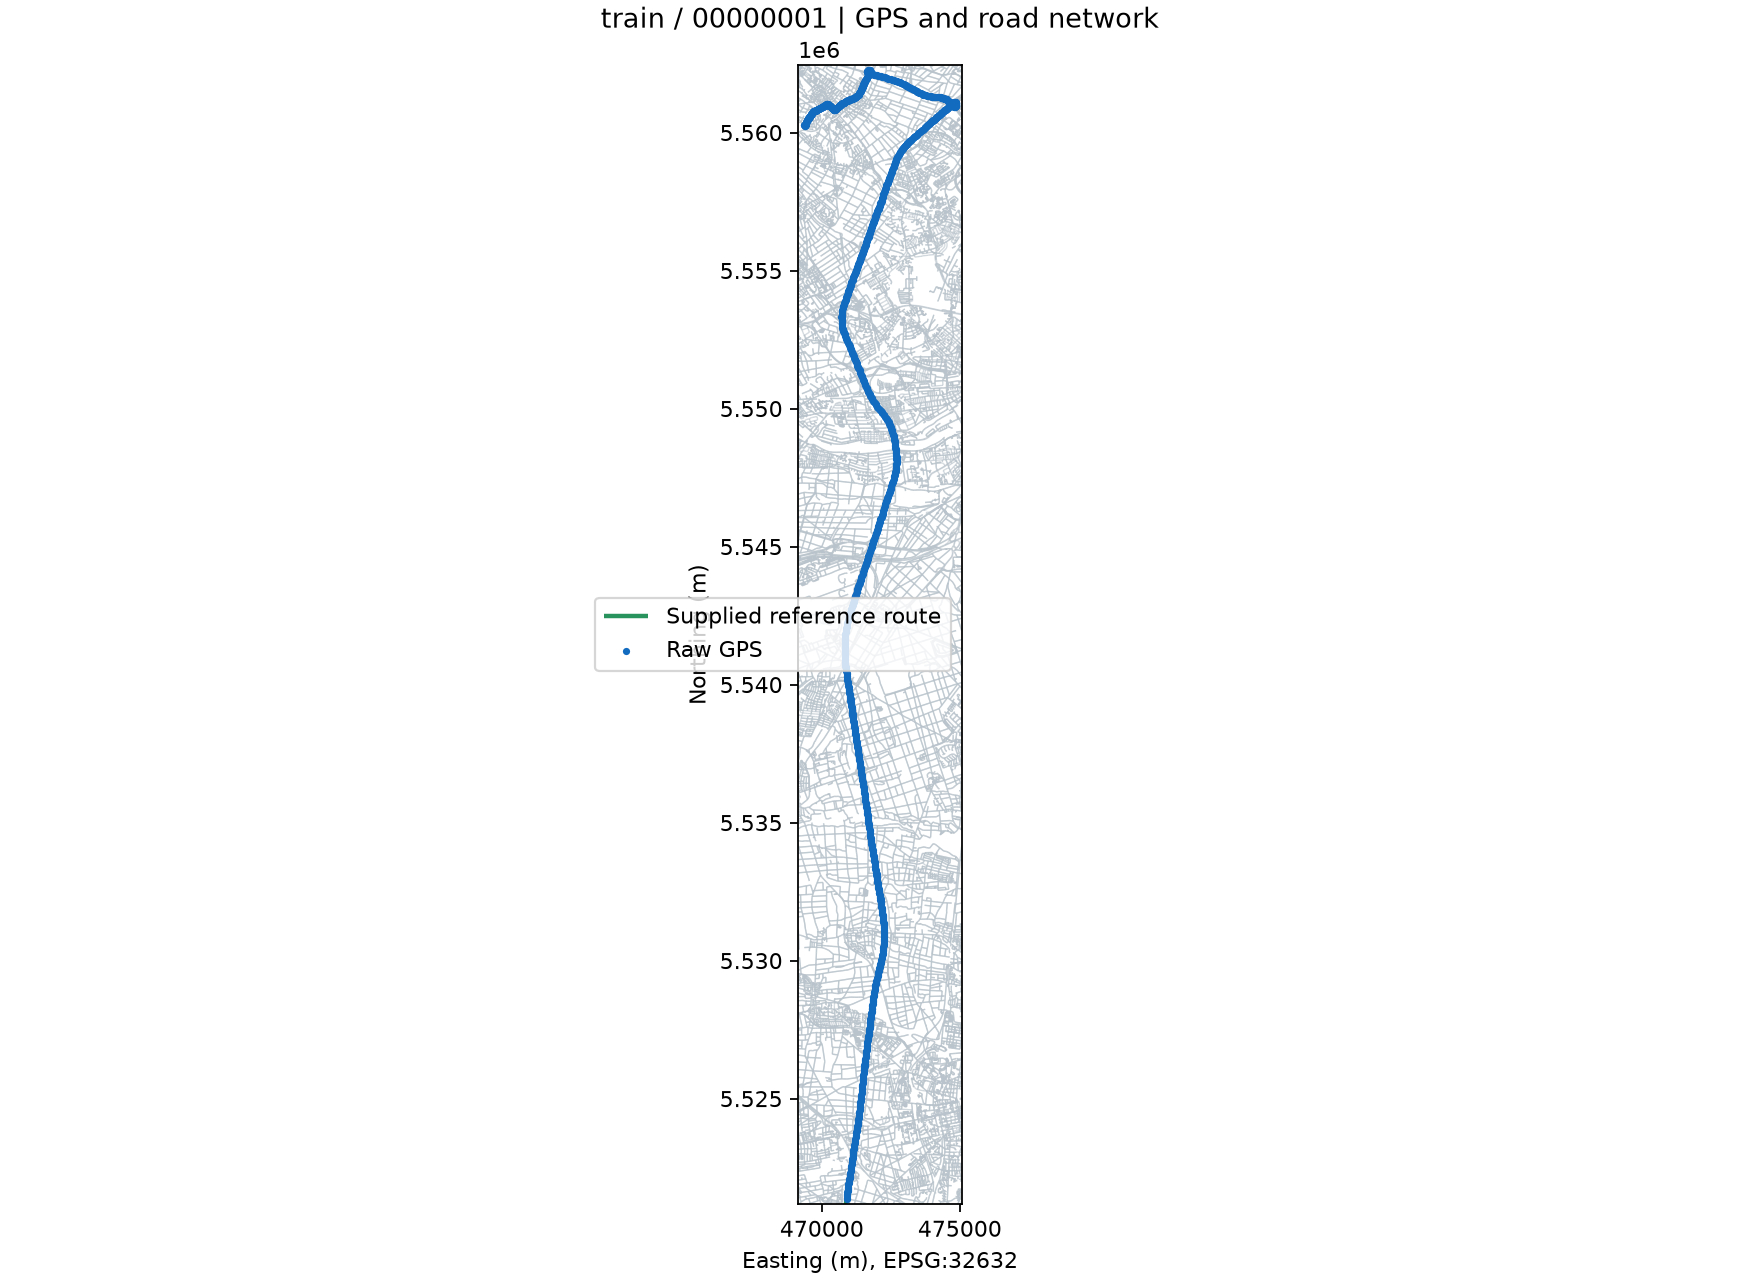

In [3]:
row = inventory.loc[inventory.partition == "train"].iloc[0]
trip = load_trip(RAW, row.partition, row.trip_id, include_reference=True)
network = RoadNetwork.from_tables(trip.nodes, trip.arcs)
track, rejected, projection = clean_track(trip.track, network.projection)
display(track[["observation_id", "timestamp_s", "dt_s", "speed_mps", "heading_valid", "gap_before"]].head(10))
print("Rejected:", len(rejected), "Metric CRS:", projection.epsg)
display(Image(filename=str(EVIDENCE / f"train_{row.trip_id}_raw_network.png")))

## Interpretation
GPS motion after gaps over 10 s is reset. Speeds over 70 m/s are flagged, not silently repaired. Coordinates are not averaged or interpolated across gaps. Initial and stationary headings are unavailable. See the saved Folium maps in `results/member1` for interactive layers; these are development EDA and must not be reused as evaluator UI reference layers.